# Improved Research Pipeline: DWT–DCT Image Steganography, CNN Steganalysis, and Integrity Checks

This revision addresses the main issues found in the previous run: fragile coefficient-parity embedding, CNN input preprocessing that converted red-channel changes to grayscale, and too few training patches/epochs. It adds a **quantization-index-modulation (QIM) DWT–DCT variant** with deterministic coefficient positions and matching extraction. The older parity method is retained only as a legacy comparator.

**Important:** QIM is a candidate improvement, not a guarantee. The notebook must pass the payload round-trip tests and report measured BER before its results are used in a paper. If QIM BER is nonzero, do not claim reliable recovery. The CNN remains a baseline; more epochs or patches do not guarantee better generalization.

**Scientific guardrails**
- Keep cover/stego pairs grouped by source image before train/validation/test splitting.
- The CNN below detects the spatial-LSB baseline unless explicitly changed; it must not be described as a DWT–DCT detector.
- SHA-256 checks are local hash comparisons, **not blockchain**. No blockchain performance values are fabricated.
- The default run uses a manageable subset of DIV2K. Increase the dataset and repeat seeds for publication-quality evaluation.

In [ ]:
# 1. Install dependencies (Google Colab)
%pip -q install opencv-python-headless PyWavelets scikit-image scikit-learn pandas matplotlib tqdm

In [ ]:
# 2. Imports and configuration
import os, time, json, hashlib, random, urllib.request, zipfile, shutil, warnings, sys
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from scipy.fftpack import dct, idct
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
ROOT = Path("/content/steg_research")
DATA_DIR = ROOT / "data"
ASSET_DIR = ROOT / "original_assets"
OUT_DIR = ROOT / "outputs"
for folder in (DATA_DIR, ASSET_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Runtime controls: increase MAX_IMAGES for a serious final evaluation.
MAX_IMAGES = 100           # None = all available DIV2K training images
IMAGE_SIZE = (512, 512)    # width, height
PAYLOAD_BPP = 0.10         # target bits per pixel for spatial-LSB reference baseline
RUN_CNN = True             # set False if CPU runtime is too limited
CNN_EPOCHS = 500
CNN_PATCH_SIZE = 64
CNN_PATCHES_PER_IMAGE = 8

print("Python:", sys.version.split()[0], "| OpenCV:", cv2.__version__)
print("Output directory:", OUT_DIR)
QIM_DELTA = 16.0  # Larger separation improves recovery but can reduce image quality; tune on validation images only.



Python: 3.13.15 | OpenCV: 4.14.0
Output directory: /content/steg_research/outputs


## 3. Download DIV2K dataset

Downloads the official DIV2K high-resolution training archive from ETH Zürich. This is a large download and requires Colab internet access. If unavailable, the notebook can instead use the original ZIP uploaded into `/content/Code (1).zip` or `/content/Code.zip`; otherwise it stops with a clear error.

In [ ]:
DIV2K_URL = "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip"
ZIP_PATH = DATA_DIR / "DIV2K_train_HR.zip"
DIV2K_DIR = DATA_DIR / "DIV2K_train_HR"

def download_div2k():
    if list(DIV2K_DIR.rglob("*.png")):
        return
    if not ZIP_PATH.exists():
        print("Downloading DIV2K high-resolution training archive; this may take a while...")
        urllib.request.urlretrieve(DIV2K_URL, ZIP_PATH)
    print("Extracting DIV2K...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)

try:
    download_div2k()
except Exception as e:
    print("DIV2K download/extraction failed:", repr(e))
    print("Trying original supplied ZIP if available...")
    candidates = [Path("/content/Code (1).zip"), Path("/content/Code.zip")]
    found = False
    for zpath in candidates:
        if zpath.exists():
            with zipfile.ZipFile(zpath) as zf:
                zf.extractall(ASSET_DIR)
            found = True
            break
    if not found:
        raise RuntimeError(
            "Dataset download failed and no supplied ZIP was found. "
            "Upload Code (1).zip to the Colab Files pane or retry the DIV2K URL."
        ) from e

div2k_images = sorted([p for p in DIV2K_DIR.rglob("*") if p.suffix.lower() in (".png", ".jpg", ".jpeg")]) if DIV2K_DIR.exists() else []
if div2k_images:
    source_paths = div2k_images
    dataset_used = "DIV2K_train_HR"
else:
    # Fall back to original cover assets included in supplied ZIP.
    candidates = []
    for base in [ASSET_DIR, Path("/content/Code/assets"), Path("/content/assets")]:
        if base.exists():
            candidates.extend([p for p in base.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png") and "secret" not in p.name.lower()])
    source_paths = sorted(set(candidates))
    dataset_used = "supplied cover assets (fallback)"
if not source_paths:
    raise FileNotFoundError("No usable cover images found. Check the dataset download or upload the supplied ZIP.")
if MAX_IMAGES is not None:
    source_paths = source_paths[:MAX_IMAGES]
print("Dataset:", dataset_used, "| images selected:", len(source_paths))
print("Examples:", [p.name for p in source_paths[:8]])

Extracting DIV2K...
Dataset: DIV2K_train_HR | images selected: 100
Examples: ['0001.png', '0002.png', '0003.png', '0004.png', '0005.png', '0006.png', '0007.png', '0008.png']


## 4. Core utilities and metrics

In [ ]:
def sha256_array(img):
    return hashlib.sha256(np.ascontiguousarray(img).tobytes()).hexdigest()

def bytes_to_bits(data):
    return np.unpackbits(np.frombuffer(data, dtype=np.uint8))

def bits_to_bytes(bits):
    bits = np.asarray(bits, dtype=np.uint8)
    return np.packbits(bits[:(len(bits)//8)*8]).tobytes()

def load_cover(path, size=IMAGE_SIZE):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        return None
    if size is not None:
        img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return img

def calculate_metrics(cover, stego):
    psnr = float(peak_signal_noise_ratio(cover, stego, data_range=255))
    cover_gray = cv2.cvtColor(cover, cv2.COLOR_BGR2GRAY)
    stego_gray = cv2.cvtColor(stego, cv2.COLOR_BGR2GRAY)
    ssim = float(structural_similarity(cover_gray, stego_gray, data_range=255))
    mse = float(np.mean((cover.astype(np.float64)-stego.astype(np.float64))**2))
    return {"PSNR_dB": psnr, "SSIM": ssim, "MSE": mse}

def dct2(a):
    return dct(dct(a.T, norm="ortho").T, norm="ortho")

def idct2(a):
    return idct(idct(a.T, norm="ortho").T, norm="ortho")

## 5. Embedding methods

**A. Legacy parity DWT–DCT comparator:** retained to reproduce the original parity approach and measure its extraction failure.

**B. QIM DWT–DCT candidate:** embeds in a deterministic pseudorandom set of red-channel Haar-LL DCT coefficients using two quantization residue classes. It is evaluated after inverse transforms and 8-bit pixel rounding. A successful round-trip must be demonstrated by BER; QIM is not assumed to work until the run proves it.

**C. Spatial-LSB reference baseline:** separate method used as a simple reference and for the current CNN task. Never attribute its results to DWT–DCT.

In [ ]:
def _qim_indices(shape, nbits, seed=SEED):
    # Deterministic keyed permutation: extraction must use the same seed and dimensions.
    rng = np.random.default_rng(seed)
    if nbits > int(np.prod(shape)):
        raise ValueError(f"Payload too large: {nbits} bits for {np.prod(shape)} LL-DCT coefficients")
    return rng.permutation(int(np.prod(shape)))[:nbits]

def embed_qim_dwt_dct(cover_bgr, payload_bytes, delta=16.0, seed=SEED):
    """DWT-Haar -> orthonormal DCT(LL) -> QIM coefficient embedding -> inverse transforms."""
    out = cover_bgr.copy()
    # OpenCV is BGR; use the red channel explicitly and consistently.
    channel = cover_bgr[:, :, 2].astype(np.float64)
    LL, (LH, HL, HH) = pywt.dwt2(channel, "haar")
    coeff = dct2(LL)
    bits = bytes_to_bits(payload_bytes)
    flat = coeff.reshape(-1).copy()
    indices = _qim_indices(flat.shape, len(bits), seed)
    # Embed bit 0 at multiples of delta, bit 1 at half-delta offsets.
    for idx, bit in zip(indices, bits):
        offset = (delta / 2.0) if int(bit) else 0.0
        flat[idx] = np.round((flat[idx] - offset) / delta) * delta + offset
    LL_modified = idct2(flat.reshape(coeff.shape))
    reconstructed = pywt.idwt2((LL_modified, (LH, HL, HH)), "haar")
    out[:, :, 2] = np.clip(np.rint(reconstructed[:cover_bgr.shape[0], :cover_bgr.shape[1]]), 0, 255).astype(np.uint8)
    return out

def extract_qim_dwt_dct(stego_bgr, payload_nbytes, delta=16.0, seed=SEED):
    channel = stego_bgr[:, :, 2].astype(np.float64)
    LL, _ = pywt.dwt2(channel, "haar")
    coeff = dct2(LL).reshape(-1)
    nbits = int(payload_nbytes) * 8
    indices = _qim_indices(coeff.shape, nbits, seed)
    values = np.mod(coeff[indices], delta)
    # Circular distance to residue 0 vs delta/2.
    dist0 = np.minimum(values, delta - values)
    dist1 = np.abs(values - delta / 2.0)
    return bits_to_bytes((dist1 < dist0).astype(np.uint8))

def embed_legacy_dwt_dct(cover_bgr, payload_bytes):
    """Legacy parity method retained for comparison; expected to be fragile after pixel rounding."""
    out = cover_bgr.copy()
    channel = cover_bgr[:, :, 2].astype(np.float64)
    LL, (LH, HL, HH) = pywt.dwt2(channel, "haar")
    coeff = dct2(LL)
    bits = bytes_to_bits(payload_bytes)
    flat = coeff.reshape(-1).copy()
    if len(bits) > len(flat):
        raise ValueError(f"Payload too large for LL-band coefficients: {len(bits)} > {len(flat)}")
    for i, bit in enumerate(bits):
        val = int(np.round(flat[i]))
        flat[i] = (val & ~1) | int(bit)
    LL_modified = idct2(flat.reshape(coeff.shape))
    reconstructed = pywt.idwt2((LL_modified, (LH, HL, HH)), "haar")
    out[:, :, 2] = np.clip(np.rint(reconstructed[:cover_bgr.shape[0], :cover_bgr.shape[1]]), 0, 255).astype(np.uint8)
    return out

def extract_legacy_dwt_dct(stego_bgr, payload_nbytes):
    channel = stego_bgr[:, :, 2].astype(np.float64)
    LL, _ = pywt.dwt2(channel, "haar")
    coeff = dct2(LL).reshape(-1)
    nbits = payload_nbytes * 8
    return bits_to_bytes(np.array([int(np.round(v)) & 1 for v in coeff[:nbits]], dtype=np.uint8))

def embed_spatial_lsb(cover_bgr, payload_bytes, bpp=PAYLOAD_BPP, channel="R"):
    stego = cover_bgr.copy()
    h, w = stego.shape[:2]
    cmap = {"B": 0, "G": 1, "R": 2}
    selected = [0, 1, 2] if channel == "RGB" else [cmap[channel]]
    payload_bits = bytes_to_bits(payload_bytes)
    cap_bits = int(h*w*bpp)
    framed = np.concatenate([
        np.unpackbits(np.frombuffer(len(payload_bytes).to_bytes(4, "big"), dtype=np.uint8)),
        payload_bits
    ])
    if len(framed) > cap_bits:
        raise ValueError(f"Payload + header ({len(framed)} bits) exceeds configured capacity ({cap_bits}).")
    plane = stego[:, :, selected].reshape(-1)
    plane[:len(framed)] = (plane[:len(framed)] & 254) | framed
    stego[:, :, selected] = plane.reshape(h, w, len(selected))
    return stego

def extract_spatial_lsb(stego_bgr, channel="R"):
    cmap = {"B": 0, "G": 1, "R": 2}
    selected = [0, 1, 2] if channel == "RGB" else [cmap[channel]]
    bits = (stego_bgr[:, :, selected].reshape(-1) & 1).astype(np.uint8)
    nbytes = int.from_bytes(bits_to_bytes(bits[:32]), "big")
    if 32 + nbytes*8 > len(bits):
        raise ValueError("Payload header invalid or wrong channel selected.")
    return bits_to_bytes(bits[32:32+nbytes*8])

# Verify exact extraction for the reference baseline.
_test = np.zeros((128,128,3), dtype=np.uint8)
_test_payload = b"round-trip verification"
_test_stego = embed_spatial_lsb(_test, _test_payload, bpp=0.10, channel="R")
assert extract_spatial_lsb(_test_stego, "R") == _test_payload
print("Spatial-LSB round-trip test: PASS")
# QIM smoke test: a low-BER result is required before using this method in research claims.
_qim_test = np.random.default_rng(SEED).integers(0, 256, (256, 256, 3), dtype=np.uint8)
_qim_payload = np.random.default_rng(SEED+1).integers(0, 256, 128, dtype=np.uint8).tobytes()
_qim_stego = embed_qim_dwt_dct(_qim_test, _qim_payload, delta=QIM_DELTA, seed=SEED)
_qim_recovered = extract_qim_dwt_dct(_qim_stego, len(_qim_payload), delta=QIM_DELTA, seed=SEED)
_qim_smoke_ber = float(np.mean(bytes_to_bits(_qim_payload) != bytes_to_bits(_qim_recovered)))
print(f"QIM smoke-test BER (must be measured, not assumed): {_qim_smoke_ber:.6f}")

Spatial-LSB round-trip test: PASS
QIM smoke-test BER (must be measured, not assumed): 0.000000


## 6. Main experiment

Runs both the legacy parity method and the QIM DWT–DCT candidate, plus a separate spatial-LSB baseline. Exports measured payload recovery, image quality, timing, difference maps, hash checks, and LSB attack results. Inspect `QIM_BER` before making any claim about the proposed transform-domain method.

In [ ]:
OUT_LEGACY = OUT_DIR / "legacy_dwt_dct"
OUT_LSB = OUT_DIR / "spatial_lsb_baseline"
for d in [OUT_LEGACY/"stego", OUT_LEGACY/"difference_maps", OUT_LSB/"stego", OUT_LSB/"difference_maps"]:
    d.mkdir(parents=True, exist_ok=True)

# Use supplied secret image if present; read as grayscale to avoid accidental 3-channel payload expansion.
secret_candidates = list(ASSET_DIR.rglob("Secret.jpg")) + list(ASSET_DIR.rglob("secret.jpg")) + list(Path("/content/Code/assets").glob("Secret.jpg"))
secret_img = cv2.imread(str(secret_candidates[0]), cv2.IMREAD_GRAYSCALE) if secret_candidates else None
if secret_img is not None:
    legacy_payload = secret_img.tobytes()
    print("Using supplied Secret.jpg as grayscale payload:", secret_img.shape, "bytes:", len(legacy_payload))
else:
    legacy_payload = None
    print("Secret.jpg not found: legacy method will use deterministic payload sized to fit each image.")

main_rows = []
ablation_rows = []
cnn_pairs = []
for idx, p in enumerate(tqdm(source_paths, desc="Running image experiments")):
    cover = load_cover(p)
    if cover is None:
        continue
    h, w = cover.shape[:2]
    max_legacy_bytes = (h//2)*(w//2)//8
    if legacy_payload is None or len(legacy_payload)*8 > (h//2)*(w//2):
        nbytes = max(1, min(max_legacy_bytes, int(h*w*0.02)//8))
        rng = np.random.default_rng(SEED + idx)
        payload_dwt = rng.integers(0, 256, nbytes, dtype=np.uint8).tobytes()
    else:
        payload_dwt = legacy_payload

    # Legacy parity comparator.
    t0 = time.perf_counter()
    try:
        stego_legacy = embed_legacy_dwt_dct(cover, payload_dwt)
        embed_dwt_s = time.perf_counter()-t0
        t1 = time.perf_counter()
        recovered_legacy = extract_legacy_dwt_dct(stego_legacy, len(payload_dwt))
        extract_dwt_s = time.perf_counter()-t1
        ber_dwt = float(np.mean(bytes_to_bits(payload_dwt) != bytes_to_bits(recovered_legacy)))
        q_dwt = calculate_metrics(cover, stego_legacy)
        dwt_error = None
        cv2.imwrite(str(OUT_LEGACY/"stego"/f"{p.stem}_legacy_stego.png"), stego_legacy)
    except Exception as e:
        embed_dwt_s = extract_dwt_s = np.nan
        ber_dwt = np.nan
        q_dwt = {"PSNR_dB": np.nan, "SSIM": np.nan, "MSE": np.nan}
        dwt_error = repr(e)
        stego_legacy = cover.copy()

    # Candidate improvement: QIM embedding. BER is measured after inverse transforms and uint8 reconstruction.
    try:
        t0 = time.perf_counter()
        stego_dwt = embed_qim_dwt_dct(cover, payload_dwt, delta=QIM_DELTA, seed=SEED)
        qim_embed_s = time.perf_counter()-t0
        t1 = time.perf_counter()
        recovered_dwt = extract_qim_dwt_dct(stego_dwt, len(payload_dwt), delta=QIM_DELTA, seed=SEED)
        qim_extract_s = time.perf_counter()-t1
        qim_ber = float(np.mean(bytes_to_bits(payload_dwt) != bytes_to_bits(recovered_dwt)))
        q_qim = calculate_metrics(cover, stego_dwt)
        cv2.imwrite(str(OUT_LEGACY/"stego"/f"{p.stem}_qim_stego.png"), stego_dwt)
        cv2.imwrite(str(OUT_LEGACY/"difference_maps"/f"{p.stem}_qim_diff.png"), (np.any(cover != stego_dwt, axis=2).astype(np.uint8)*255))
    except Exception as e:
        qim_embed_s = qim_extract_s = np.nan
        qim_ber = np.nan
        q_qim = {"PSNR_dB": np.nan, "SSIM": np.nan, "MSE": np.nan}
        qim_error = repr(e)
    else:
        qim_error = None

    # Spatial-LSB baseline, red channel; payload bytes fit configured bpp.
    nbytes_lsb = max(0, (int(h*w*PAYLOAD_BPP)-32)//8)
    rng = np.random.default_rng(SEED + 10000 + idx)
    payload_lsb = rng.integers(0, 256, nbytes_lsb, dtype=np.uint8).tobytes()
    t0 = time.perf_counter()
    stego_lsb = embed_spatial_lsb(cover, payload_lsb, PAYLOAD_BPP, "R")
    embed_lsb_s = time.perf_counter()-t0
    t1 = time.perf_counter()
    recovered_lsb = extract_spatial_lsb(stego_lsb, "R")
    extract_lsb_s = time.perf_counter()-t1
    ber_lsb = float(np.mean(bytes_to_bits(payload_lsb) != bytes_to_bits(recovered_lsb))) if payload_lsb else 0.0
    q_lsb = calculate_metrics(cover, stego_lsb)
    cv2.imwrite(str(OUT_LSB/"stego"/f"{p.stem}_stego.png"), stego_lsb)
    cv2.imwrite(str(OUT_LSB/"difference_maps"/f"{p.stem}_diff.png"), (np.any(cover != stego_lsb, axis=2).astype(np.uint8)*255))

    tampered = stego_lsb.copy()
    tampered[0,0,0] ^= 1
    hash_detected = sha256_array(tampered) != sha256_array(stego_lsb)

    # Robustness tests for the spatial-LSB reference only; lossy transforms will normally destroy LSB data.
    attack_records = {}
    attack_images = {}
    ok, enc = cv2.imencode(".jpg", stego_lsb, [cv2.IMWRITE_JPEG_QUALITY, 90])
    attack_images["jpeg_q90"] = cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else stego_lsb.copy()
    noise_rng = np.random.default_rng(SEED + 20000 + idx)
    attack_images["gaussian_noise_sigma1"] = np.clip(stego_lsb.astype(np.float32)+noise_rng.normal(0,1,stego_lsb.shape),0,255).astype(np.uint8)
    attack_images["median_3x3"] = cv2.medianBlur(stego_lsb,3)
    dh,dw=max(1,int(h*.05)),max(1,int(w*.05))
    attack_images["crop5_resize"] = cv2.resize(stego_lsb[dh:h-dh,dw:w-dw],(w,h),interpolation=cv2.INTER_LINEAR)
    for aname, aimg in attack_images.items():
        try:
            rec = extract_spatial_lsb(aimg, "R")
            n = min(len(payload_lsb), len(rec))
            ber = float(np.mean(bytes_to_bits(payload_lsb[:n]) != bytes_to_bits(rec[:n]))) if n else 1.0
            exact = rec == payload_lsb
        except Exception:
            ber, exact = 1.0, False
        attack_records[f"BER_{aname}"] = ber
        attack_records[f"exact_{aname}"] = exact

    main_rows.append({
        "image": p.name, "width": w, "height": h,
        "legacy_payload_bytes": len(payload_dwt), "legacy_payload_bpp": len(payload_dwt)*8/(h*w),
        "legacy_DWT_DCT_PSNR_dB": q_dwt["PSNR_dB"], "legacy_DWT_DCT_SSIM": q_dwt["SSIM"],
        "legacy_DWT_DCT_MSE": q_dwt["MSE"], "legacy_embed_sec": embed_dwt_s,
        "legacy_extract_sec": extract_dwt_s, "legacy_BER": ber_dwt, "legacy_error": dwt_error,
        "QIM_DWT_DCT_PSNR_dB": q_qim["PSNR_dB"], "QIM_DWT_DCT_SSIM": q_qim["SSIM"],
        "QIM_DWT_DCT_MSE": q_qim["MSE"], "QIM_embed_sec": qim_embed_s,
        "QIM_extract_sec": qim_extract_s, "QIM_BER": qim_ber, "QIM_error": qim_error,
        "LSB_payload_bytes": len(payload_lsb), "LSB_payload_bpp": len(payload_lsb)*8/(h*w),
        "LSB_PSNR_dB": q_lsb["PSNR_dB"], "LSB_SSIM": q_lsb["SSIM"], "LSB_MSE": q_lsb["MSE"],
        "LSB_embed_sec": embed_lsb_s, "LSB_extract_sec": extract_lsb_s, "LSB_BER": ber_lsb,
        "LSB_exact_recovery": recovered_lsb == payload_lsb,
        "local_SHA256_tamper_detected": hash_detected, **attack_records
    })
    cnn_pairs.append((p.stem, cover, stego_lsb))

results_df = pd.DataFrame(main_rows)
results_df.to_csv(OUT_DIR/"main_results.csv", index=False)
display(results_df.head())
print("Saved main results:", OUT_DIR/"main_results.csv")
print("LSB exact recovery all images:", bool(results_df["LSB_exact_recovery"].all()))

Secret.jpg not found: legacy method will use deterministic payload sized to fit each image.


Running image experiments:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


,image,width,height,legacy_payload_bytes,legacy_payload_bpp,legacy_DWT_DCT_PSNR_dB,legacy_DWT_DCT_SSIM,legacy_DWT_DCT_MSE,legacy_embed_sec,legacy_extract_sec,...,LSB_exact_recovery,local_SHA256_tamper_detected,BER_jpeg_q90,exact_jpeg_q90,BER_gaussian_noise_sigma1,exact_gaussian_noise_sigma1,BER_median_3x3,exact_median_3x3,BER_crop5_resize,exact_crop5_resize
0,0001.png,512,512,655,0.019989,inf,1.0,0.0,0.030887,0.019577,...,True,True,1.0,False,1.0,False,1.0,False,1.0,False
1,0002.png,512,512,655,0.019989,inf,1.0,0.0,0.043782,0.031621,...,True,True,1.0,False,1.0,False,1.0,False,1.0,False
2,0003.png,512,512,655,0.019989,inf,1.0,0.0,0.026301,0.017812,...,True,True,1.0,False,1.0,False,1.0,False,1.0,False
3,0004.png,512,512,655,0.019989,inf,1.0,0.0,0.025155,0.017860,...,True,True,1.0,False,1.0,False,1.0,False,1.0,False
4,0005.png,512,512,655,0.019989,inf,1.0,0.0,0.030805,0.019405,...,True,True,1.0,False,1.0,False,1.0,False,1.0,False


Saved main results: /content/steg_research/outputs/main_results.csv
LSB exact recovery all images: True


## 7. Channel ablation for the spatial-LSB reference

Compares R, G, B, and RGB embedding at a matched total payload rate. These results apply to spatial LSB only and must not be described as DWT-DCT channel ablation.

In [ ]:
for name, cover, _ in tqdm(cnn_pairs, desc="Channel ablation"):
    h,w=cover.shape[:2]
    nbytes=max(0,(int(h*w*PAYLOAD_BPP)-32)//8)
    rng=np.random.default_rng(SEED+sum(map(ord,name)))
    payload=rng.integers(0,256,nbytes,dtype=np.uint8).tobytes()
    for channel in ["R","G","B","RGB"]:
        t0=time.perf_counter()
        stego=embed_spatial_lsb(cover,payload,PAYLOAD_BPP,channel)
        elapsed=time.perf_counter()-t0
        recovered=extract_spatial_lsb(stego,channel)
        q=calculate_metrics(cover,stego)
        ablation_rows.append({"image":name,"channel":channel,**q,"payload_bytes":len(payload),
                              "effective_bpp":len(payload)*8/(h*w),"embed_sec":elapsed,
                              "BER":float(np.mean(bytes_to_bits(payload)!=bytes_to_bits(recovered))) if payload else 0.0,
                              "exact_recovery":recovered==payload})
ablation_df=pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUT_DIR/"channel_ablation.csv",index=False)
display(ablation_df.groupby("channel")[["PSNR_dB","SSIM","MSE","embed_sec","BER"]].mean().round(6))

Channel ablation:   0%|          | 0/100 [00:00<?, ?it/s]

,PSNR_dB,SSIM,MSE,embed_sec,BER
channel,,,,,
B,65.909230,0.999968,0.016679,0.000754,0.0
G,65.916204,0.999693,0.016652,0.000669,0.0
R,65.913809,0.999901,0.016661,0.001088,0.0
RGB,65.917775,0.999892,0.016646,0.003816,0.0


## 8. CNN steganalysis baseline (optional)

The CNN uses three separate channel residuals rather than grayscale residuals, and more patches/epochs than the earlier run. This is still a small starter model and currently uses **spatial-LSB cover/stego pairs**, not the QIM DWT–DCT pairs. Near-chance results may still be scientifically plausible for a weakly detectable payload; do not tune against the test set.

Epoch 1/500: train=0.6944, val=0.6935
Epoch 2/500: train=0.6931, val=0.6933
Epoch 3/500: train=0.6929, val=0.6932
Epoch 4/500: train=0.6932, val=0.6932
Epoch 5/500: train=0.6941, val=0.6932
Epoch 6/500: train=0.6939, val=0.6933
Epoch 7/500: train=0.6939, val=0.6932
Epoch 8/500: train=0.6925, val=0.6932
Epoch 9/500: train=0.6936, val=0.6932
Epoch 10/500: train=0.6940, val=0.6933
Epoch 11/500: train=0.6929, val=0.6932
Epoch 12/500: train=0.6928, val=0.6932
Epoch 13/500: train=0.6935, val=0.6931
Epoch 14/500: train=0.6932, val=0.6932
Epoch 15/500: train=0.6927, val=0.6932
Epoch 16/500: train=0.6937, val=0.6931
Epoch 17/500: train=0.6939, val=0.6931
Epoch 18/500: train=0.6932, val=0.6931
Epoch 19/500: train=0.6935, val=0.6932
Epoch 20/500: train=0.6928, val=0.6931
Epoch 21/500: train=0.6926, val=0.6931
Epoch 22/500: train=0.6936, val=0.6932
Epoch 23/500: train=0.6924, val=0.6931
Epoch 24/500: train=0.6929, val=0.6931
Epoch 25/500: train=0.6935, val=0.6931
Epoch 26/500: train=0.6935, val=0.

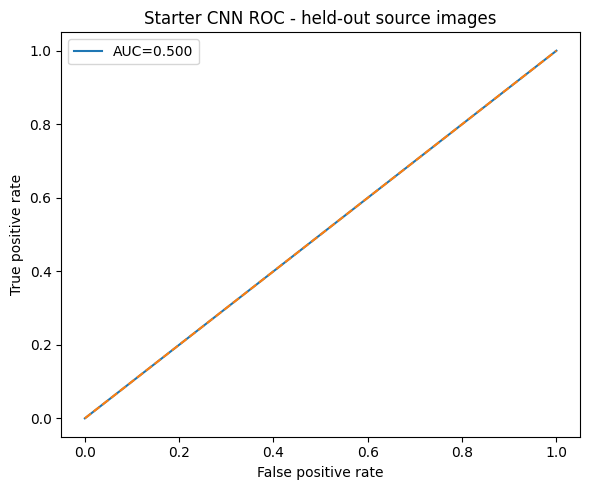

{
  "status": "completed",
  "device": "cuda",
  "train_source_images": 68,
  "validation_source_images": 12,
  "test_source_images": 20,
  "test_patch_count": 320,
  "accuracy": 0.5,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.5,
  "epochs": 500,
  "seed": 42
}


In [ ]:
cnn_summary = {"status":"disabled"}
if RUN_CNN:
    try:
        import torch
        import torch.nn as nn
        from torch.utils.data import Dataset, DataLoader

        names=[x[0] for x in cnn_pairs]
        if len(names) < 20:
            cnn_summary={"status":"skipped","reason":"Need at least 20 source images for this starter split."}
            print(cnn_summary)
        else:
            train_names,test_names=train_test_split(names,test_size=.2,random_state=SEED)
            train_names,val_names=train_test_split(train_names,test_size=.15,random_state=SEED)
            pairmap={n:(c,s) for n,c,s in cnn_pairs}

            def make_patches(subset):
                X,y=[],[]
                rng=np.random.default_rng(SEED)
                ps=CNN_PATCH_SIZE
                for n in subset:
                    cover,stego=pairmap[n]
                    h,w=cover.shape[:2]
                    for _ in range(CNN_PATCHES_PER_IMAGE):
                        yy=int(rng.integers(0,h-ps+1)); xx=int(rng.integers(0,w-ps+1))
                        for img,label in ((cover,0),(stego,1)):
                            # Preserve channel-specific high-frequency traces; do not grayscale away red-channel LSB changes.
                            patch=img[yy:yy+ps,xx:xx+ps].astype(np.float32)/255.0
                            residual=np.stack([patch[:,:,ch]-cv2.GaussianBlur(patch[:,:,ch],(3,3),0) for ch in range(3)],axis=0)
                            X.append(residual); y.append(label)
                return np.asarray(X,dtype=np.float32),np.asarray(y,dtype=np.int64)

            Xtr,ytr=make_patches(train_names); Xv,yv=make_patches(val_names); Xte,yte=make_patches(test_names)
            class PatchDataset(Dataset):
                def __init__(self,X,y): self.X=torch.from_numpy(X); self.y=torch.from_numpy(y)
                def __len__(self): return len(self.y)
                def __getitem__(self,i): return self.X[i],self.y[i]
            device="cuda" if torch.cuda.is_available() else "cpu"
            train_loader=DataLoader(PatchDataset(Xtr,ytr),batch_size=64,shuffle=True)
            val_loader=DataLoader(PatchDataset(Xv,yv),batch_size=128,shuffle=False)
            test_loader=DataLoader(PatchDataset(Xte,yte),batch_size=128,shuffle=False)

            class ResidualCNN(nn.Module):
                def __init__(self):
                    super().__init__()
                    self.net=nn.Sequential(
                        nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                        nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                        nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(1),
                        nn.Flatten(),nn.Linear(64,32),nn.ReLU(),nn.Dropout(.3),nn.Linear(32,1))
                def forward(self,x): return self.net(x).squeeze(1)

            model=ResidualCNN().to(device)
            optimizer=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
            criterion=nn.BCEWithLogitsLoss()
            best=float("inf"); best_state=None; history=[]
            for epoch in range(CNN_EPOCHS):
                model.train(); train_losses=[]
                for xb,yb in train_loader:
                    xb,yb=xb.to(device),yb.float().to(device)
                    optimizer.zero_grad(); loss=criterion(model(xb),yb); loss.backward(); optimizer.step()
                    train_losses.append(loss.item())
                model.eval(); val_losses=[]
                with torch.no_grad():
                    for xb,yb in val_loader:
                        xb,yb=xb.to(device),yb.float().to(device)
                        val_losses.append(criterion(model(xb),yb).item())
                v=float(np.mean(val_losses))
                history.append({"epoch":epoch+1,"train_loss":float(np.mean(train_losses)),"val_loss":v})
                print(f"Epoch {epoch+1}/{CNN_EPOCHS}: train={np.mean(train_losses):.4f}, val={v:.4f}")
                if v<best:
                    best=v; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            if best_state: model.load_state_dict(best_state)
            model.eval(); probs=[]; labels=[]
            with torch.no_grad():
                for xb,yb in test_loader:
                    probs.extend(torch.sigmoid(model(xb.to(device))).cpu().numpy().tolist())
                    labels.extend(yb.numpy().tolist())
            labels=np.asarray(labels); probs=np.asarray(probs); pred=(probs>=.5).astype(int)
            cnn_summary={"status":"completed","device":device,"train_source_images":len(train_names),
                "validation_source_images":len(val_names),"test_source_images":len(test_names),
                "test_patch_count":int(len(labels)),"accuracy":float(accuracy_score(labels,pred)),
                "precision":float(precision_score(labels,pred,zero_division=0)),
                "recall":float(recall_score(labels,pred,zero_division=0)),
                "f1":float(f1_score(labels,pred,zero_division=0)),
                "roc_auc":float(roc_auc_score(labels,probs)),"epochs":CNN_EPOCHS,"seed":SEED}
            with open(OUT_DIR/"cnn_metrics.json","w") as f: json.dump(cnn_summary,f,indent=2)
            pd.DataFrame(history).to_csv(OUT_DIR/"cnn_training_history.csv",index=False)
            fpr,tpr,_=roc_curve(labels,probs)
            plt.figure(figsize=(6,5)); plt.plot(fpr,tpr,label=f"AUC={cnn_summary['roc_auc']:.3f}")
            plt.plot([0,1],[0,1],"--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
            plt.title("Starter CNN ROC - held-out source images"); plt.legend(); plt.tight_layout()
            plt.savefig(OUT_DIR/"cnn_roc.png",dpi=300); plt.show()
            print(json.dumps(cnn_summary,indent=2))
    except Exception as e:
        cnn_summary={"status":"failed","error":repr(e)}
        print("CNN stage failed; other results remain available:",repr(e))
        with open(OUT_DIR/"cnn_error.txt","w") as f: f.write(repr(e))

## 9. Figures and exports

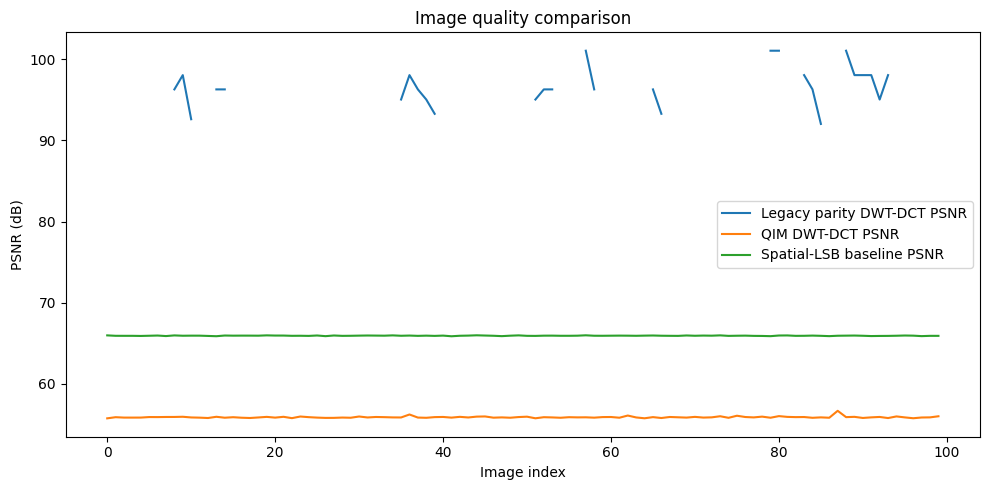

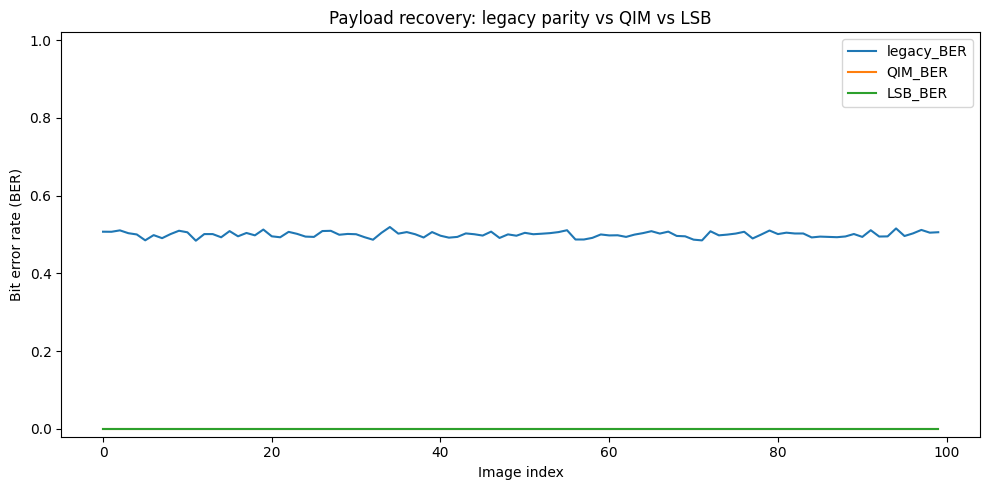

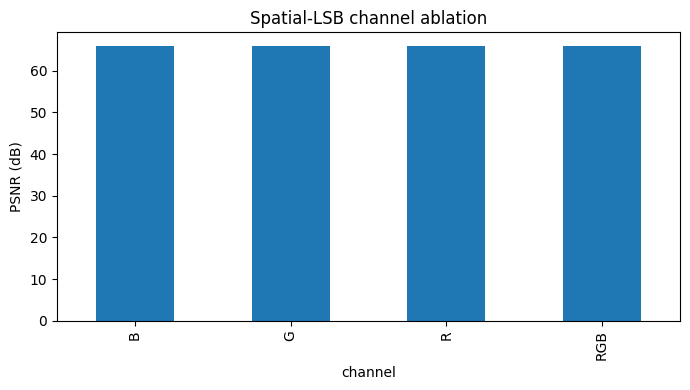

{
  "dataset": "DIV2K_train_HR",
  "selected_images": 100,
  "image_size": [
    512,
    512
  ],
  "payload_bpp_spatial_lsb_target": 0.1,
  "seed": 42,
  "legacy_DWT_DCT_mean_finite_PSNR_dB": 96.7188492198701,
  "legacy_DWT_DCT_infinite_PSNR_count": 62,
  "legacy_DWT_DCT_mean_SSIM": 0.999999980127225,
  "legacy_DWT_DCT_mean_BER": 0.5001393129770992,
  "QIM_DWT_DCT_mean_finite_PSNR_dB": 55.862140175168285,
  "QIM_DWT_DCT_mean_SSIM": 0.9993303564320422,
  "QIM_DWT_DCT_mean_BER": 0.0,
  "QIM_DWT_DCT_exact_recovery_rate": 1.0,
  "spatial_LSB_mean_PSNR_dB": 65.9129190597902,
  "spatial_LSB_mean_SSIM": 0.9999009203063918,
  "spatial_LSB_mean_BER": 0.0,
  "spatial_LSB_all_exact_recovery": true,
  "local_hash_tamper_detected_all": true,
  "cnn": {
    "status": "completed",
    "device": "cuda",
    "train_source_images": 68,
    "validation_source_images": 12,
    "test_source_images": 20,
    "test_patch_count": 320,
    "accuracy": 0.5,
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0

In [ ]:
if len(results_df):
    plt.figure(figsize=(10,5))
    plt.plot(results_df["legacy_DWT_DCT_PSNR_dB"].replace([np.inf, -np.inf], np.nan),label="Legacy parity DWT-DCT PSNR")
    plt.plot(results_df["QIM_DWT_DCT_PSNR_dB"].replace([np.inf, -np.inf], np.nan),label="QIM DWT-DCT PSNR")
    plt.plot(results_df["LSB_PSNR_dB"].replace([np.inf, -np.inf], np.nan),label="Spatial-LSB baseline PSNR")
    plt.ylabel("PSNR (dB)"); plt.xlabel("Image index"); plt.title("Image quality comparison")
    plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR/"fig_quality_comparison.png",dpi=300); plt.show()

    plt.figure(figsize=(8,5))
    results_df[["legacy_BER","QIM_BER","LSB_BER"]].plot(kind="line",ax=plt.gca(),figsize=(10,5))
    plt.ylabel("Bit error rate (BER)"); plt.xlabel("Image index"); plt.title("Payload recovery: legacy parity vs QIM vs LSB")
    plt.ylim(-0.02,1.02)
    plt.tight_layout(); plt.savefig(OUT_DIR/"fig_ber_comparison.png",dpi=300); plt.show()

    ab_summary=ablation_df.groupby("channel")[["PSNR_dB","SSIM","MSE","BER"]].mean()
    ax=ab_summary["PSNR_dB"].plot(kind="bar",figsize=(7,4),ylabel="PSNR (dB)",title="Spatial-LSB channel ablation")
    plt.tight_layout(); plt.savefig(OUT_DIR/"fig_channel_ablation.png",dpi=300); plt.show()

summary={
    "dataset":dataset_used,"selected_images":len(source_paths),"image_size":list(IMAGE_SIZE),
    "payload_bpp_spatial_lsb_target":PAYLOAD_BPP,"seed":SEED,
    "legacy_DWT_DCT_mean_finite_PSNR_dB":float(results_df["legacy_DWT_DCT_PSNR_dB"].replace([np.inf,-np.inf],np.nan).mean()),
    "legacy_DWT_DCT_infinite_PSNR_count":int(np.isinf(results_df["legacy_DWT_DCT_PSNR_dB"]).sum()),
    "legacy_DWT_DCT_mean_SSIM":float(results_df["legacy_DWT_DCT_SSIM"].mean()),
    "legacy_DWT_DCT_mean_BER":float(results_df["legacy_BER"].mean()),
    "QIM_DWT_DCT_mean_finite_PSNR_dB":float(results_df["QIM_DWT_DCT_PSNR_dB"].replace([np.inf,-np.inf],np.nan).mean()),
    "QIM_DWT_DCT_mean_SSIM":float(results_df["QIM_DWT_DCT_SSIM"].mean()),
    "QIM_DWT_DCT_mean_BER":float(results_df["QIM_BER"].mean()),
    "QIM_DWT_DCT_exact_recovery_rate":float((results_df["QIM_BER"] == 0).mean()),
    "spatial_LSB_mean_PSNR_dB":float(results_df["LSB_PSNR_dB"].mean()),
    "spatial_LSB_mean_SSIM":float(results_df["LSB_SSIM"].mean()),
    "spatial_LSB_mean_BER":float(results_df["LSB_BER"].mean()),
    "spatial_LSB_all_exact_recovery":bool(results_df["LSB_exact_recovery"].all()),
    "local_hash_tamper_detected_all":bool(results_df["local_SHA256_tamper_detected"].all()),
    "cnn":cnn_summary,
    "blockchain":{"status":"not implemented; no blockchain performance metrics generated"},
    "QIM_delta":QIM_DELTA,
    "warning":"QIM is a candidate method; verify BER and quality trade-off. Spatial-LSB metrics are a separate baseline."
}
with open(OUT_DIR/"summary.json","w") as f: json.dump(summary,f,indent=2)
with open(OUT_DIR/"run_manifest.json","w") as f:
    json.dump({"python":sys.version,"opencv":cv2.__version__,"numpy":np.__version__,
        "seed":SEED,"dataset":dataset_used,"image_paths":[str(p) for p in source_paths]},f,indent=2)
print(json.dumps(summary,indent=2))
print("All results and figures saved to:",OUT_DIR)

## 10. Interpretation and next steps for the manuscript

- Compare `legacy_BER` against `QIM_BER`. Only report reliable transform-domain recovery if QIM BER is acceptably low across images and payload rates.
- Report PSNR/SSIM together with payload BER; high visual similarity alone does not establish a functioning hiding method.
- The spatial-LSB results are a separate reference baseline and must not be described as DWT–DCT results.
- The CNN detects spatial-LSB examples in this notebook. For a DWT–DCT detector, rebuild `cnn_pairs` using the QIM stego images and rerun the source-level split.
- SHA-256 here is a local integrity check, not a blockchain deployment. Blockchain performance claims require an actual implementation and measurements.
- For a paper, use a larger image set, several seeds, confidence intervals, a held-out test set, and predeclared payload rates. Tune `QIM_DELTA` only on training/validation data; report the selected value and all test metrics transparently.